__aims__: 
- Use these V2 screens for ScreenPro2 DevOps

__tasks__: 
- [ ] compare ScreenProcessing guide level scores with ScreenPro2 scores.

- score distribution

- p-value distribution

- question for Luke: https://github.com/ArcInstitute/ScreenPro2/issues/85

### load tools

In [1]:
!pip uninstall -y screenpro2
# !pip install git+https://github.com/ArcInstitute/ScreenPro2.git@dev
# !pip install /home/abe/tools/ScreenPro2
!pip install ScreenPro2

Found existing installation: ScreenPro2 0.6.0
Uninstalling ScreenPro2-0.6.0:
  Successfully uninstalled ScreenPro2-0.6.0
Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com
Processing /home/abe/tools/ScreenPro2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for ScreenPro2: filename=screenpro2-0.6.0-py3-none-any.whl size=44115 sha256=fcb9d2b3c86bd944d5d89622ddbb605545735437ceb08118499ba98086b6ad60
  Stored in directory: /tmp/pip-ephem-wheel-cache-nuotl99t/wheels/d1/ce/dd/feeb25e101b3360ddcec2131370ce2dde823ab01d8ded8ca66
Successfully built ScreenPro2


In [2]:
import numpy as np
import pandas as pd
import anndata as ad
import screenpro as scp
from venn import venn
from glob import glob
import blitzgsea as blitz
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib import rcParams, rc_context
from matplotlib import font_manager as fm

from matplotlib import rcParams, rc_context

# font_files = fm.findSystemFonts(fontpaths=None, fontext='ttf')

# for font_file in font_files:
#     fm.fontManager.addfont(font_file)
# # {f.name for f in matplotlib.font_manager.fontManager.ttflist}

# rcParams['font.family'] = ['Arial']

In [3]:
import matplotlib_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('png')

### Gather data

In [4]:
# # get counts
# for exp_id in ['hl60_exp1','skm1_exp','molm13_exp']:
#     for table_id in ['phenotypetable','mergedcountstable','genetable_collapsed']:
#         !wget -P dac_screens/{exp_id}/ \
#             https://raw.githubusercontent.com/GilbertLabUCSF/Decitabine-treatment/main/DAC/CRISPRi-screen/{exp_id}/{table_id}.txt &> /dev/null

In [5]:
# # http://humantfs.ccbr.utoronto.ca/download.php
# # TF gene names (.txt)
# !wget -P ../annotations http://humantfs.ccbr.utoronto.ca/download/v_1.01/TF_names_v_1.01.txt

In [6]:
# TFs_list = pd.read_csv('../annotations/TF_names_v_1.01.txt',header=None)[0].to_list()

### Run `guidecounter`

In [7]:
CRISPRi_v2_human_path = '../CRISPRi_v2_human_librarytable.txt.gz'

In [8]:
library_table = pd.read_csv(
    CRISPRi_v2_human_path,
    sep = '\t', index_col=False, low_memory=False)

In [9]:
counter = scp.GuideCounter(cas_type = 'cas9', library_type = 'single_guide_design')
counter.load_library(CRISPRi_v2_human_path, sep = '\t', verbose = True, index_col=None, protospacer_length=19)

Trimming protospacer sequences in 'protospacer' column.
Library table successfully loaded.
total # of cas9 sgRNAs: 205648


___

In [10]:
fq_dir = '/home/abe/projects/AML/Decitabine-treatment/DAC/CRISPRi-screen/molm13_exp/fastq/'


samples = []

for fq_file in glob(f'{fq_dir}/*.fastq.gz'):
    if 'GSK' not in fq_file:
        sample_id = fq_file.split('/')[-1].replace('.fastq.gz','')
        # sample_id = fq_file.split('/')[1].split('.')[0].split('_S')[0]
        samples.append(sample_id)

samples.sort()

samples

['DAC_Rep1', 'DAC_Rep2', 'DMSO_Rep1', 'DMSO_Rep2', 'T0_Rep1', 'T0_Rep2']

In [11]:
# %%bash
# ls -lh /home/abea/AML/Decitabine-treatment/DAC/CRISPRi-screen/molm13_exp/fastq/*fastq.gz

In [12]:
counter.get_counts_matrix(
    fastq_dir = fq_dir,
    samples = samples,
    trim_first_g=True,
    # write = 'force',
    verbose = True
)

DAC_Rep1
count file exists ...
% mapped reads 89.53479376867612
DAC_Rep2
count file exists ...
% mapped reads 89.37213429785241
DMSO_Rep1
count file exists ...
% mapped reads 89.44755293464992
DMSO_Rep2
count file exists ...
% mapped reads 89.52737426713749
T0_Rep1
count file exists ...
% mapped reads 89.80417738922552
T0_Rep2
count file exists ...
% mapped reads 89.73240842907204


In [13]:
counter.counts_mat.sum() / 10**6

DAC_Rep1     78.043097
DAC_Rep2     73.136989
DMSO_Rep1    90.083288
DMSO_Rep2    80.543484
T0_Rep1      79.574007
T0_Rep2      85.000360
dtype: float64

In [14]:
db_untreated=10.04
db_treated=7.46

In [15]:
adata = counter.build_counts_anndata()

adata.obs = pd.DataFrame(
    adata.obs.index.map(lambda x: x.split('_')[-2:]).to_list(),
    columns = ['condition','replicate'],
    index = adata.obs.index
)
adata.obs['replicate'] = adata.obs['replicate'].str[-1].astype(int)

adata.var['targetType'] = [
    'gene' if t != 'negative_control' else 'negative_control' for t in 
    adata.var.target
]

adata.obs['pop_doubling'] = [db_treated,db_treated,db_untreated,db_untreated,np.nan,np.nan]

adata.var['transcript'] = library_table.set_index('sgId').loc[adata.var.index, 'transcripts']

___

In [16]:
# # add transcript annotation!
# adata.var.loc[adata.var['target'] != "negative_control",'target'] = pd.concat([
#     adata.var.query('target != "negative_control"')['target'], 
#     library_table.set_index('sgId')['transcripts'][adata.var.query('target != "negative_control"').index]
# ],axis=1).agg("-".join, axis=1)

___

### Run `phenoscore`

In [21]:
molm13_screen = scp.PooledScreens(adata, verbose=True, n_reps=2)

molm13_screen.filterLowCounts(minimum_reads=40)
# molm13_screen.filterLowCounts()

molm13_screen.countNormalization()

113302 variables with less than 40 reads (filter_type: 'all')
Pseudocount added to counts.
Counts normalized by sequencing depth.


___

In [22]:
# help(scp.ps.runPhenoScore)

In [23]:
# del molm13_screen.phenotypes['compare_guides_top_3']

In [24]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    # count_filter_type='either',
    keep_top_n = 3,
    run_name='compare_guides_top_3',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


___

In [21]:
# del molm13_screen.phenotypes['compare_guides_all']

In [25]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    count_filter_type='either',
    run_name='compare_guides_all',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


___

In [26]:
molm13_screen.calculateDrugScreenDESeq(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
)

	creating `dds` object...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 8.22 seconds.

Fitting dispersion trend curve...
... done in 1.80 seconds.

/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 8.84 seconds.

Fitting LFCs...
... done in 6.04 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 0 outlier genes.

Running Wald tests...


	DMSO_vs_T0


... done in 3.12 seconds.



	DAC_vs_T0


Running Wald tests...
... done in 3.09 seconds.



	DAC_vs_DMSO


Running Wald tests...
... done in 3.08 seconds.



___

In [27]:
molm13_screen.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_reps',
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


___

#### Load ScreenProcessing

In [50]:
data_dir = '../dac_screens/'

molm13_screenprocessing_data = scp.load.loadScreenProcessingData(f'{data_dir}/MOLM13_CRISPRi_DAC')

molm13_screenprocessing_counts = molm13_screenprocessing_data['counts']

molm13_screenprocessing_counts.columns = molm13_screen.adata.obs.index.to_list()

molm13_screenprocessing = ad.AnnData(
    X = molm13_screenprocessing_counts.T,
    obs = adata.obs,
    var = library_table.set_index('sgId').loc[molm13_screenprocessing_counts.index.to_list(),]
)
molm13_screenprocessing.var.rename(columns={'gene':'target','transcripts':'transcript'}, inplace=True)

molm13_screenprocessing.var['targetType'] = [
    'gene' if t != 'negative_control' else 'negative_control' for t in 
    molm13_screenprocessing.var.target
]

molm13_screenprocessing = scp.PooledScreens(molm13_screenprocessing, verbose=True, n_reps=2)

In [51]:
# molm13_screenprocessing=molm13_screenprocessing[
#     :,pd.concat([molm13_screenprocessing.var.head(100), molm13_screenprocessing.var.tail(1000)]).index].copy()

___

Run ScreenPro2 on ScreenProcessing counts:

In [52]:
# del molm13_screenprocessing.adata.obs['pop_doublings']

In [53]:
molm13_screenprocessing.filterLowCounts(minimum_reads=40)

molm13_screenprocessing.countNormalization()

11351 variables with less than 40 reads (filter_type: 'all')
Pseudocount added to counts.
Counts normalized by sequencing depth.


___

In [54]:
# del molm13_screenprocessing.phenotypes['compare_guides_top_3']

In [55]:
molm13_screenprocessing.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    count_filter_type='either',
    keep_top_n = 3,
    run_name='compare_guides_top_3',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


In [56]:
# del molm13_screenprocessing.phenotypes['compare_guides_all']

In [57]:
molm13_screenprocessing.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_guides',
    count_filter_type='either',
    run_name='compare_guides_all',
    var_names=['target','transcript'],
    # collapse_var='target'
)

	DMSO vs T0


	DAC vs T0
	DAC vs DMSO


___

In [58]:
molm13_screenprocessing.calculateDrugScreenDESeq(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    # score_level='compare_guides',
    # run_name='compare_guides_all'
)

	creating `dds` object...
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.02 seconds.

Fitting dispersions...
... done in 8.29 seconds.

Fitting dispersion trend curve...


... done in 1.70 seconds.

/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pydeseq2/dds.py:548: UserWarning: As the residual degrees of freedom is less than 3, the distribution of log dispersions is especially asymmetric and likely to be poorly estimated by the MAD.
  self.fit_dispersion_prior()
Fitting MAP dispersions...
... done in 8.97 seconds.

Fitting LFCs...
... done in 6.04 seconds.

Calculating cook's distance...
... done in 0.03 seconds.

Replacing 0 outlier genes.

Running Wald tests...


	DMSO_vs_T0


... done in 2.96 seconds.



	DAC_vs_T0


Running Wald tests...
... done in 3.13 seconds.



	DAC_vs_DMSO


Running Wald tests...
... done in 3.16 seconds.



___

In [59]:
molm13_screenprocessing.calculateDrugScreen(
    t0 = 'T0',
    untreated = 'DMSO',
    treated = 'DAC',
    score_level='compare_reps',
)

	DMSO vs T0
	DAC vs T0
	DAC vs DMSO


In [60]:
molm13_screenprocessing.listPhenotypeScores('compare_guides_top_3')

['gamma:DMSO_vs_T0', 'tau:DAC_vs_T0', 'rho:DAC_vs_DMSO']

___

Add ScreenProcessing gene-level and transcript-level results to the `PooledScreens` object:

In [61]:
molm13_screenprocessing.phenotypes['geneTable'] = {'results':{}}

for score_name in molm13_screenprocessing.phenotypes['compare_reps']['results'].keys():
    score_df = molm13_screenprocessing_data['gene scores'][score_name.split(':')[0]]['ave_Rep1_Rep2'].reset_index().rename(columns={'gene':'target'})
    score_df.index = score_df['target']
    score_df.loc[score_df['target'].str.contains('pseudo'),'target'] = 'negative_control'

    molm13_screenprocessing.phenotypes['geneTable']['results'].update({score_name: score_df})

In [62]:
molm13_screenprocessing.phenotypes['transcriptTable'] = {'results':{}}

for score_name in molm13_screenprocessing.phenotypes['compare_reps']['results'].keys():
    score_df = molm13_screenprocessing_data['transcript scores'][score_name.split(':')[0]]['ave_Rep1_Rep2'].reset_index().rename(columns={'gene':'target'})
        
    # add transcript annotation!
    score_df.loc[~score_df['target'].str.contains("pseudo"),'target'] = score_df.query('target != "negative_control"')[['target','transcripts']].agg('-'.join,axis=1)
    score_df.index = score_df['target'].to_list()

    score_df.loc[score_df['target'].str.contains('pseudo'),'target'] = 'negative_control'
    
    molm13_screenprocessing.phenotypes['transcriptTable']['results'].update({score_name: score_df})

___

In [63]:
scp.load._write_screen_pkl(molm13_screen,'molm13_screen')

Object successfully saved to "molm13_screen.pkl"


In [64]:
scp.load._write_screen_pkl(molm13_screenprocessing,'molm13_screenprocessing')

Object successfully saved to "molm13_screenprocessing.pkl"


### Compare guide level scores

In [66]:
from scipy.stats import gaussian_kde

def scatter_with_gaussian_kde(ax, x, y):
    # https://stackoverflow.com/a/20107592/3015186
    # Answer by Joel Kington

    xy = np.vstack([x, y])
    z = gaussian_kde(xy)(xy)

    ax.scatter(x, y, c=z, s=10) #, edgecolor=''

In [67]:
d1 = molm13_screenprocessing_data['phenotypes']['rho']['Rep1'].dropna()

d2 = scp.ps.getPhenotypeData(
    molm13_screenprocessing.adata,
    score_tag='rho',
    cond_ref='DMSO',cond_test='DAC',
    growth_rate_reps = {1:db_untreated - db_treated, 2:db_untreated - db_treated},
    # growth_rate_reps = {1:db_untreated, 2:db_untreated},
).to_df().loc['rho:DAC_vs_DMSO::replicate_1'].dropna()

d3 = scp.ps.getPhenotypeData(
    molm13_screen.adata,
    score_tag='rho',
    cond_ref='DMSO',cond_test='DAC',
    growth_rate_reps = {1:db_untreated - db_treated, 2:db_untreated - db_treated},
    # growth_rate_reps = {1:db_untreated, 2:db_untreated},
).to_df().loc['rho:DAC_vs_DMSO::replicate_1'].dropna()


ol = list(set(d1.index) & set(d2.index) & set(d3.index))
ol.sort()

___

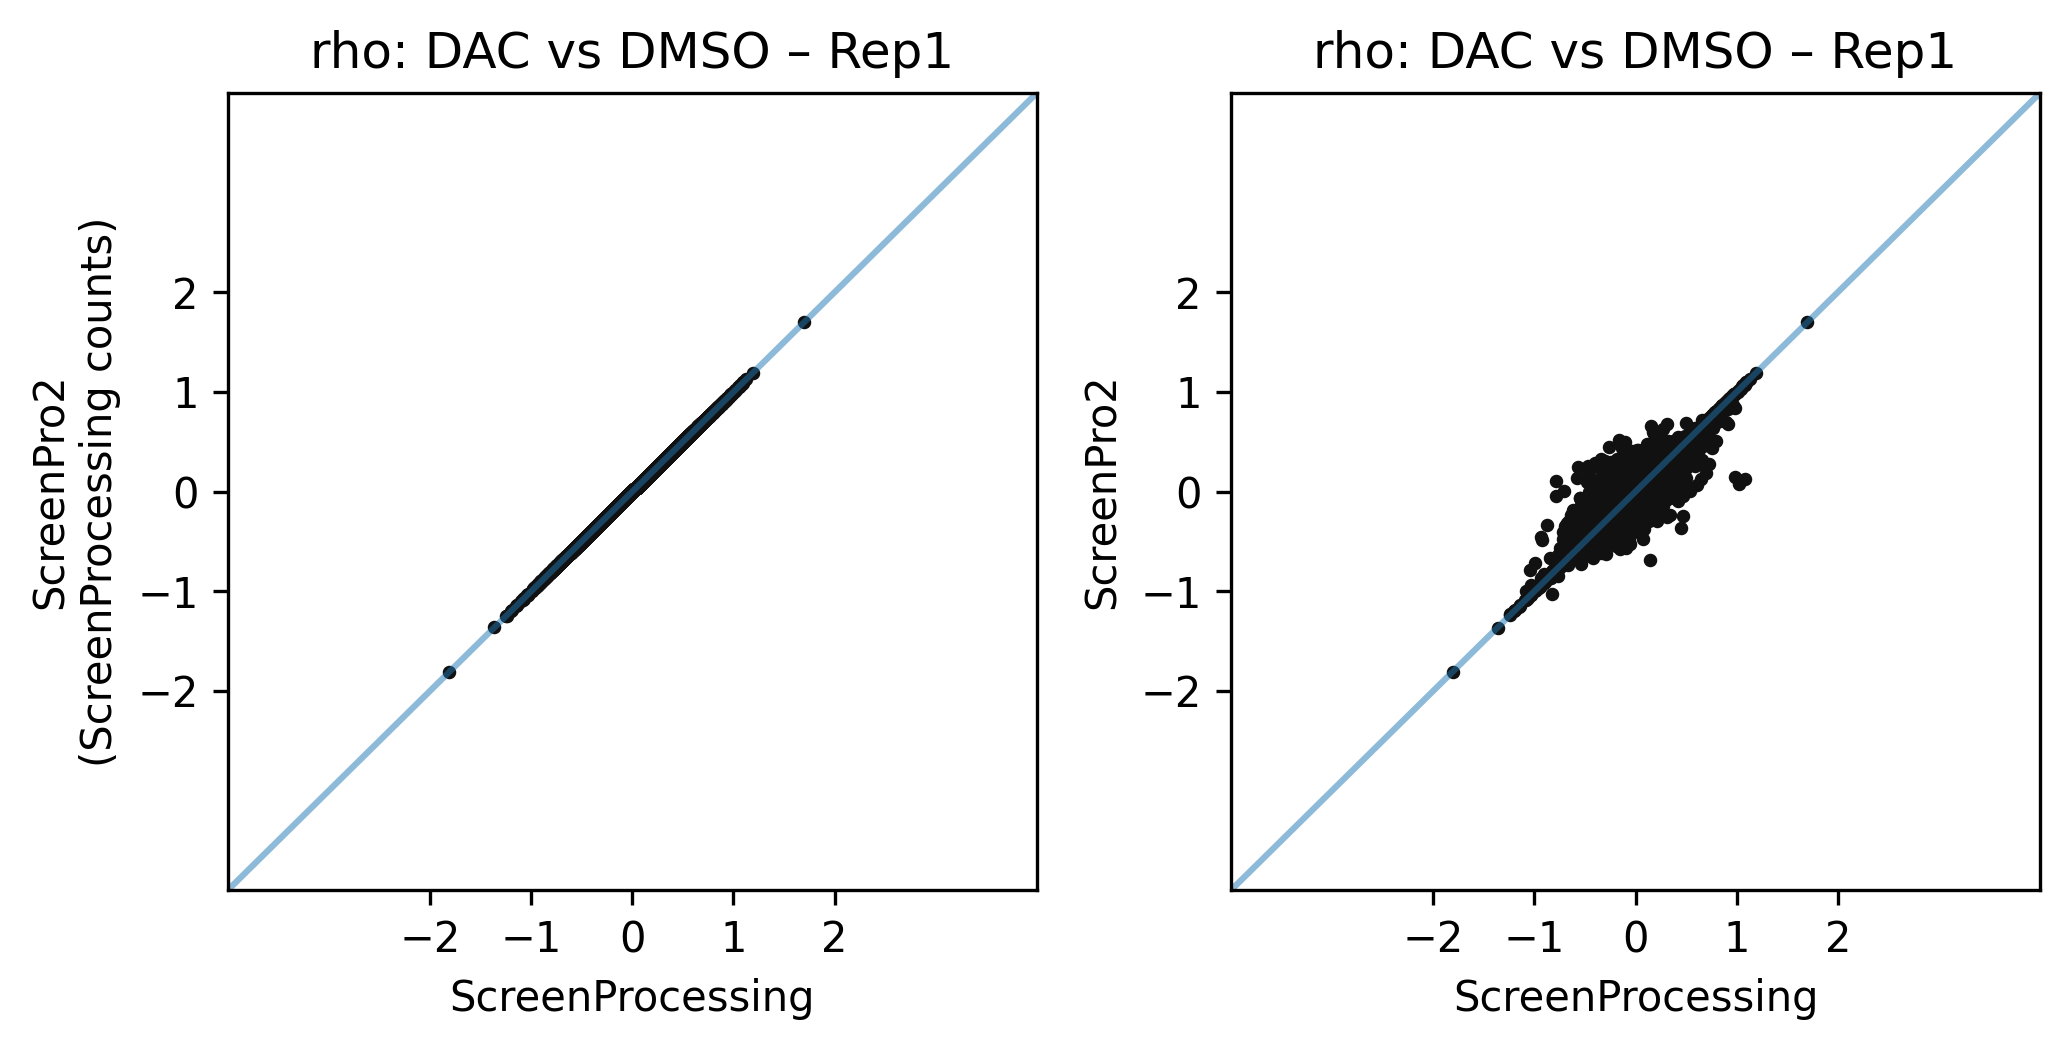

In [68]:
fig, axes = plt.subplots(1,2,figsize=(7,3.6), dpi=300)

# scatter_with_gaussian_kde(
#    ax=axes[0],
axes[0].scatter(
    x=d1[ol],
    y=d2[ol],
    s=5,
    color=scp.pl._utils.almost_black
)

axes[0].set_xlabel('ScreenProcessing')
axes[0].set_ylabel('ScreenPro2\n(ScreenProcessing counts)')
axes[0].set_title('rho: DAC vs DMSO – Rep1',fontsize=12)

# scatter_with_gaussian_kde(
#     ax=axes[1],
axes[1].scatter(
    x=d1[ol],
    y=d3[ol],
    s=5,
    color=scp.pl._utils.almost_black
)

axes[1].set_xlabel('ScreenProcessing')
axes[1].set_ylabel('ScreenPro2')

axes[1].set_title('rho: DAC vs DMSO – Rep1',fontsize=12)

for ax in axes: 
    ax.axline((0, 0), slope=1, alpha=.5)
    ax.set_xlim(-4,4)
    ax.set_ylim(-4,4)
    
    ax.set_xticks(np.linspace(-2,2,5))
    ax.set_yticks(np.linspace(-2,2,5))

plt.tight_layout()
plt.show()

In [69]:
molm13_screenprocessing

In [70]:
d1 = molm13_screenprocessing.phenotypes['transcriptTable'
]['results']['rho:DAC_vs_DMSO'].dropna().query('~index.duplicated()')['average phenotype of strongest 3']

d2 = molm13_screenprocessing.phenotypes['compare_guides_all' #compare_guides_top_3
]['results']['rho:DAC_vs_DMSO'].dropna().query('~index.duplicated()').sort_values(
    ['target','ttest pvalue']
)['score']

d3 = molm13_screen.phenotypes['compare_guides_all' #compare_guides_top_3'
]['results']['rho:DAC_vs_DMSO'].dropna().query('~index.duplicated()').sort_values(
    ['target','ttest pvalue']
)['score']

ol = list(set(d1.index) & set(d2.index) & set(d3.index))
ol = [t for t in ol if 'pseudo' not in t]
ol.sort()

In [71]:
len(ol)

20056

___

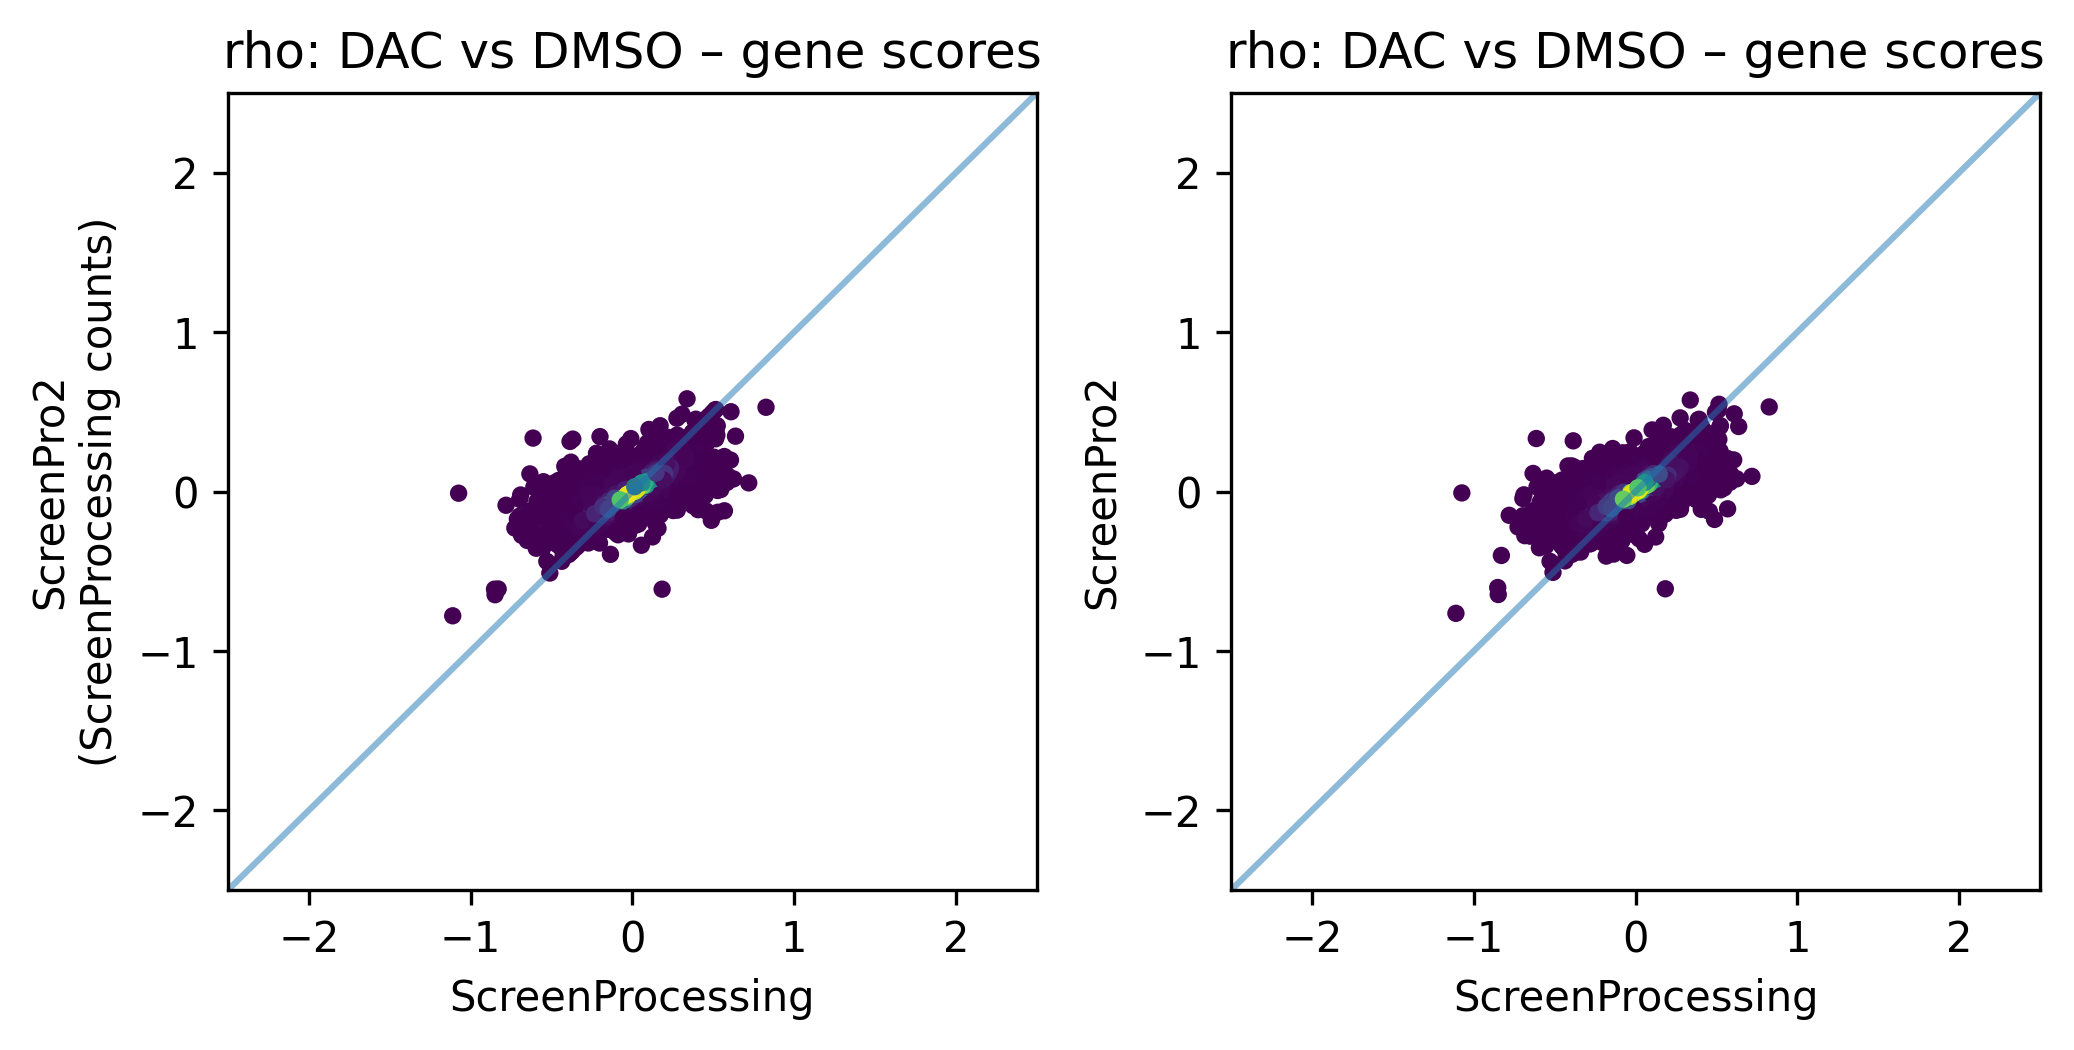

In [72]:
fig, axes = plt.subplots(1,2,figsize=(7,3.6), dpi=300)

scatter_with_gaussian_kde(
    ax=axes[0],
    x=d1[ol],
    y=d2[ol],
)

axes[0].set_xlabel('ScreenProcessing')
axes[0].set_ylabel('ScreenPro2\n(ScreenProcessing counts)')
axes[0].set_title('rho: DAC vs DMSO – gene scores',fontsize=12)

# axes[1].set_visible(False)

scatter_with_gaussian_kde(
    ax=axes[1],
    x=d1[ol],
    y=d3[ol],
)

axes[1].set_xlabel('ScreenProcessing')
axes[1].set_ylabel('ScreenPro2')
axes[1].set_title('rho: DAC vs DMSO – gene scores',fontsize=12)

for ax in axes: 
    ax.axline((0, 0), slope=1, alpha=.5)
    ax.set_xlim(-2.5,2.5)
    ax.set_ylim(-2.5,2.5)
    
    # ax.set_xticks(np.linspace(-2,2,5))
    # ax.set_yticks(np.linspace(-2,2,5))

plt.tight_layout()
plt.show()

## Evaluation metrics

### AUC-ROC
CommonEssentials

In [ ]:
from sklearn import metrics
from sklearn.metrics import precision_recall_curve
import matplotlib.lines as mlines

In [112]:
# from screenpro.phenoscore.evaluate import calcPR, calcROC

import numpy as np
from sklearn import metrics
from sklearn.metrics import precision_recall_curve
import matplotlib.lines as mlines


def calcROC(df_in, essential, nonessential, score_col, target_col='target', verbose=False):
    df = df_in.copy()
    # df[target_col] = df[target_col].str.split('-').str[0]
    
    # AUC-ROC
    df['DepMap'] = [
        'essential' if target in essential else 
        'non_essential' if target in nonessential else 
        np.nan for target in df[target_col]
    ]

    y_true = df[df['DepMap'].notna()]['DepMap']
    y_scores = df[df['DepMap'].notna()][score_col]
    
    fpr, tpr, thresholds = metrics.roc_curve(y_true, y_scores, pos_label='non_essential')
    
    if verbose: print('ROC-AUC score:', metrics.roc_auc_score(y_true, y_scores))
    
    return fpr, tpr


def calcPR(df_in, truePos, trueNeg, score_col, target_col='target', ascending=True, verbose=False):

    df = df_in.copy()

    scoreList = df.set_index(target_col)[score_col]

    truePos = truePos.intersection(scoreList.index)
    trueNeg = trueNeg.intersection(scoreList.index)
    
    cumulativeTup = [(0,1,np.nan)]
    cumulativeTP = 0.0
    cumulativeFP = 0.0
    
    tup_cross95 = None
    
    for gene, fold_change in scoreList.sort_values(inplace=False, ascending=ascending).items():
        if gene in truePos or gene in trueNeg:
            if gene in truePos:
                cumulativeTP += 1

            elif gene in trueNeg:
                cumulativeFP += 1

            cumulativeTup.append((cumulativeTP / len(truePos), cumulativeTP / (cumulativeTP + cumulativeFP), fold_change))
    
    tup_cross95 = [cross95 for cross95 in cumulativeTup[::-1] if cross95[1] >= 0.95][0]
    
    if verbose: print('Precision-Recall AUC:', tup_cross95)
    
    return cumulativeTup, tup_cross95


In [113]:
DepMap_essential = pd.read_csv(
    '/home/abe/tools/CanDI/CanDI/setup/data/depmap/21Q4/common_essentials.csv', sep=' '
).index.to_list()
DepMap_essential = list(set(DepMap_essential) & \
                        set(library_table.query('gene != "negative_control"')['gene']))

DepMap_nonessential = pd.read_csv(
    '/home/abe/tools/CanDI/CanDI/setup/data/depmap/21Q4/nonessentials.csv', sep=' '
).index.to_list()

DepMap_nonessential = list(set(DepMap_nonessential) & \
                           set(library_table.query('gene != "negative_control"')['gene']))


___

In [114]:
gamma_screenprocessing = molm13_screenprocessing.phenotypes['geneTable']['results']['gamma:DMSO_vs_T0']

gamma_screenprocessing = scp.ps.annotateScoreTable(
    gamma_screenprocessing,
    up_hit=scp.ps._annotate.hit_dict['gamma']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['gamma']['down_hit'],
    ctrl_label='negative_control',
    score_col='average phenotype of strongest 3',
    pvalue_col='Mann-Whitney p-value',
    threshold=1
)

gamma_screenprocessing.dropna(inplace=True)

gamma_screenprocessing = gamma_screenprocessing.query(
    'target != "negative_control"')

In [115]:
gamma_screenpro2 = molm13_screen.phenotypes['compare_guides_top_3']['results']['gamma:DMSO_vs_T0']

gamma_screenpro2 = scp.ps.annotateScoreTable(
    gamma_screenpro2,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=1
)

gamma_screenpro2.dropna(inplace=True)

gamma_screenpro2 = gamma_screenpro2.query('target != "negative_control"')

In [116]:
gamma_screenpro2_with_screenprocessing_counts = molm13_screenprocessing.phenotypes['compare_guides_top_3']['results']['gamma:DMSO_vs_T0']

gamma_screenpro2_with_screenprocessing_counts = scp.ps.annotateScoreTable(
    gamma_screenpro2_with_screenprocessing_counts,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=1
)
gamma_screenpro2_with_screenprocessing_counts.dropna(inplace=True)

gamma_screenpro2_with_screenprocessing_counts = gamma_screenpro2_with_screenprocessing_counts.query('target != "negative_control"')

In [117]:
# gamma_pyDESeq2_with_screenprocessing_counts = molm13_screenprocessing.phenotypes['pyDESeq2']['results']['gamma:DMSO_vs_T0']

# gamma_pyDESeq2_with_screenprocessing_counts = scp.ps.annotateScoreTable(
#     gamma_pyDESeq2_with_screenprocessing_counts,
#     up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
#     down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
#     ctrl_label='negative_control',
#     score_col='log2FoldChange',
#     pvalue_col='pvalue',
#     threshold=1
# )

# gamma_pyDESeq2_with_screenprocessing_counts = gamma_pyDESeq2_with_screenprocessing_counts.sort_values('pvalue').drop_duplicates('target',keep='first')

# gamma_pyDESeq2_with_screenprocessing_counts.dropna(inplace=True)

# gamma_pyDESeq2_with_screenprocessing_counts = gamma_pyDESeq2_with_screenprocessing_counts.query('target != "negative_control"')

___

In [118]:
ol = list(
    set(gamma_screenpro2['target']) & \
    set(gamma_screenprocessing['target']) & \
    set(gamma_screenpro2_with_screenprocessing_counts['target'])
)

In [119]:
df = gamma_screenprocessing.query(f'target in {ol}').copy()
target_col = 'average phenotype of strongest 3'
essential=DepMap_essential
nonessential=DepMap_nonessential


# df[target_col] = df[target_col].str.split('-').str[0]
# df[target_col]
# # AUC-ROC
df['DepMap'] = ['essential' if target in essential else 'non_essential' if target in nonessential else np.nan for target in df[target_col]]

In [120]:
gamma_screenprocessing_fpr, gamma_screenprocessing_tpr = calcROC(
    gamma_screenprocessing.query(f'target in {ol}'),
    score_col = 'average phenotype of strongest 3',
    # score_col = 'Mann-Whitney p-value',
    # score_col = 'combined_score'
    essential=DepMap_essential,
    nonessential=DepMap_nonessential
)

In [121]:
gamma_screenpro2_fpr, gamma_screenpro2_tpr = calcROC(
    gamma_screenpro2.query(f'target in {ol}'), 
    # score_col = 'ttest pvalue'
    score_col = 'score',
    # score_col = 'combined_score'
    essential=DepMap_essential,
    nonessential=DepMap_nonessential
)

In [122]:
gamma_screenpro2_with_screenprocessing_counts_fpr, gamma_screenpro2_with_screenprocessing_counts_tpr = calcROC(
    gamma_screenpro2_with_screenprocessing_counts.query(f'target in {ol}'), 
    # score_col = 'ttest pvalue'
    score_col = 'score',
    # score_col = 'combined_score'
    essential=DepMap_essential,
    nonessential=DepMap_nonessential
)

In [123]:
# gamma_pyDESeq2_with_screenprocessing_counts_fpr, gamma_pyDESeq2_with_screenprocessing_counts_tpr = DepMap_AUC_ROC(
#     gamma_pyDESeq2_with_screenprocessing_counts.query(f'target in {ol}'), 
#     score_col = 'log2FoldChange'
#     # score_col = 'combined_score'
# )

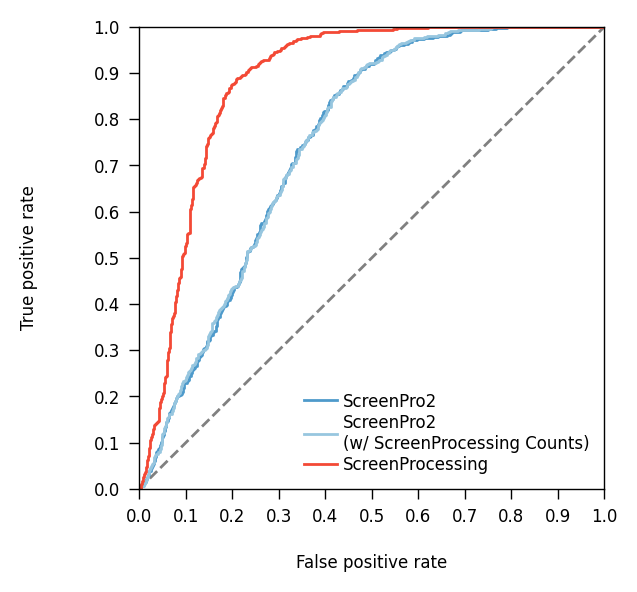

In [124]:
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)

#colors = iter(['#8dd8ce', '#bfbfbf', '#ffcc66', '#a7e382'])
colors = iter([plt.cm.Blues(150), plt.cm.Blues(100), plt.cm.Reds(150), plt.cm.Reds(100)])

plt.plot(
    gamma_screenpro2_fpr, 
    gamma_screenpro2_tpr, 
    label='ScreenPro2', color=next(colors), linewidth=1
)
plt.plot(
    gamma_screenpro2_with_screenprocessing_counts_fpr, 
    gamma_screenpro2_with_screenprocessing_counts_tpr, 
    label='ScreenPro2\n(w/ ScreenProcessing Counts)',
    color=next(colors), linewidth=1
)

# plt.plot(
#     gamma_pyDESeq2_with_screenprocessing_counts_fpr, 
#     gamma_pyDESeq2_with_screenprocessing_counts_tpr, 
#     label='pyDESeq2\n(w/ ScreenProcessing Counts)',
#     color=next(colors), linewidth=1
# )

plt.plot(
    gamma_screenprocessing_fpr, 
    gamma_screenprocessing_tpr, 
    label='ScreenProcessing', color=next(colors), linewidth=1
)

line = mlines.Line2D([0, 100], [0, 100], color='grey', linestyle='--', linewidth = 1, zorder=0)
transform = ax.transAxes
line.set_transform(transform)
ax.add_line(line)

min_val = 0
max_val = 1

plt.ylim(bottom= min_val, top=max_val)
plt.xlim(left= min_val, right=max_val)

# plt.gca().spines['right'].set_color('none')
# plt.gca().spines['top'].set_color('none')
#plt.title('DepMap', fontsize=14, pad=10) #21Q1
plt.xlabel('False positive rate', fontsize=12, labelpad=10)
plt.ylabel('True positive rate', fontsize=12, labelpad=20)
plt.xticks(np.arange(0,1.2,0.2))
plt.tick_params(labelsize=24, bottom=True, left=True)
plt.xticks(np.linspace(0,1,11))
plt.yticks(np.linspace(0,1,11))

plt.legend(
    ncol=1, fontsize=6, frameon=False, 
    handletextpad=0.35, labelspacing=0.20, title='', title_fontsize=12,
    loc='lower right'
) #AUC = 0.95-0.89

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(.5)
ax.tick_params(width=.5)

for item in ([ax.title]):
    item.set_fontsize(8)
for item in ([ax.xaxis.label, ax.yaxis.label]):
    item.set_fontsize(6)
for item in ax.get_xticklabels() + ax.get_yticklabels():
    item.set_fontsize(6)

#plt.savefig('/home/tdfair/Desktop/ROC.pdf', bbox_inches='tight', dpi=750)
plt.show()

Precision-Recall

In [125]:
gamma_screenprocessing_cumulativeTup, gamma_screenprocessing_tup_cross95 = calcPR(
    gamma_screenprocessing,
    # gamma_screenprocessing[''], 
    truePos=set(DepMap_essential), 
    trueNeg=set(DepMap_nonessential),
    score_col='average phenotype of strongest 3'
    # combined_score
    # 'Mann-Whitney p-value'
)

gamma_screenpro2_cumulativeTup, gamma_screenpro2_tup_cross95 = calcPR(
    gamma_screenpro2, 
    truePos=set(DepMap_essential), 
    trueNeg=set(DepMap_nonessential),
    score_col='score'
)

# gamma_pyDESeq2_with_screenprocessing_counts_cumulativeTup, gamma_pyDESeq2_with_screenprocessing_counts_tup_cross95 = calcPR(
#     gamma_pyDESeq2_with_screenprocessing_counts['log2FoldChange'], 
#     # gamma_screenpro2_with_screenprocessing_counts['ttest pvalue'], 
#     set(DepMap_essential), set(DepMap_nonessential))

gamma_screenpro2_with_screenprocessing_counts_cumulativeTup, gamma_screenpro2_with_screenprocessing_counts_tup_cross95 = calcPR(
    # gamma_screenpro2_with_screenprocessing_counts['ttest pvalue'], 
    gamma_screenpro2_with_screenprocessing_counts,
    # gamma_screenpro2_with_screenprocessing_counts['combined_score'], 
    truePos=set(DepMap_essential), 
    trueNeg=set(DepMap_nonessential),
    score_col='score'
)

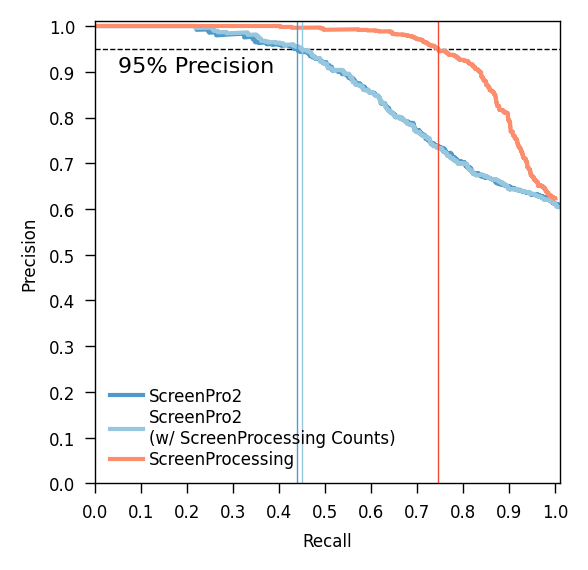

In [126]:
fig, ax = plt.subplots(figsize=(3, 3), dpi=200)

colors = [plt.cm.Blues(150), plt.cm.Blues(100), plt.cm.Reds(150), plt.cm.Reds(100)]

plt.plot([recall[0] for recall in gamma_screenpro2_cumulativeTup], 
         [precision[1] for precision in gamma_screenpro2_cumulativeTup], label='ScreenPro2', c=colors[0])

plt.plot([recall[0] for recall in gamma_screenpro2_with_screenprocessing_counts_cumulativeTup], 
         [precision[1] for precision in gamma_screenpro2_with_screenprocessing_counts_cumulativeTup], 
         label='ScreenPro2\n(w/ ScreenProcessing Counts)',
         # label='ScreenPro2', 
         c=colors[1])

# plt.plot([recall[0] for recall in gamma_pyDESeq2_with_screenprocessing_counts_cumulativeTup], 
#          [precision[1] for precision in gamma_pyDESeq2_with_screenprocessing_counts_cumulativeTup], 
#          label='pyDESeq2', c=colors[2])

plt.plot([recall[0] for recall in gamma_screenprocessing_cumulativeTup], 
         [precision[1] for precision in gamma_screenprocessing_cumulativeTup], 
         label='ScreenProcessing', 
         c=colors[3])

plt.axvline(gamma_screenpro2_tup_cross95[0], lw=.5, c=colors[0])
plt.axvline(gamma_screenpro2_with_screenprocessing_counts_tup_cross95[0], lw=.5, c=colors[1])
plt.axvline(gamma_screenprocessing_tup_cross95[0], lw=.5, c=colors[2])

for item in ([ax.title]):
    item.set_fontsize(8)
for item in ([ax.xaxis.label, ax.yaxis.label]):
    item.set_fontsize(6)
for item in ax.get_xticklabels() + ax.get_yticklabels():
    item.set_fontsize(6)

for axis in ['top','bottom','left','right']:
    ax.spines[axis].set_linewidth(.5)
ax.tick_params(width=.5)

plt.xlim(0,1.01)
plt.ylim(0,1.01)
plt.xticks(np.linspace(0,1,11))
plt.yticks(np.linspace(0,1,11))
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.axhline(0.95, c='black', lw=0.5, ls='--', zorder=0)
plt.text(0.05, 0.9, '95% Precision', fontsize=8)

plt.legend(
    ncol=1, fontsize=6, frameon=False,
    handletextpad=0.35, labelspacing=0.20, title='', title_fontsize=12,
    loc='lower left'
)

plt.tick_params(bottom=True, left=True)

#plt.savefig('/home/tyler/Desktop/PR_curve_hCRISPRi-v2.png', bbox_inches='tight', dpi=300)
plt.show()

---

In [86]:
# fig, ax1 = plt.subplots(1,1,figsize=(3,4))

# ## draw venn diagram
# n_top_hits = 100

# # resistance_hit
# venn(
#     {
#         'CommonEssentials':set(DepMap_essential),
#         'CommonNonEssentials':set(DepMap_nonessential),
#         'ScreenProcessing Essentials':set(gamma_screenprocessing['target'].to_list()),
#     }, ax=ax1,
#     # legend_loc=None
# )

# # plt.title('Sensitivity hits', fontsize=22)
# plt.show()

### Compare scores

In [127]:
rho_screenprocessing = molm13_screenprocessing.phenotypes['geneTable']['results']['rho:DAC_vs_DMSO']

rho_screenprocessing = scp.ps.annotateScoreTable(
    rho_screenprocessing,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    score_col='average phenotype of strongest 3',
    pvalue_col='Mann-Whitney p-value',
    threshold=5
)

rho_screenprocessing = rho_screenprocessing.query('target != "negative_control"')

In [128]:
rho_screenprocessing.groupby('label').size()

label
sensitivity_hit      128
resistance_hit       117
target_non_hit     18660
dtype: int64

In [129]:
rho_screenpro2 = molm13_screen.phenotypes['compare_guides_top_3']['results']['rho:DAC_vs_DMSO']

rho_screenpro2 = scp.ps.annotateScoreTable(
    rho_screenpro2,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=2
)

rho_screenpro2 = rho_screenpro2.query('target != "negative_control"')


In [130]:
rho_screenpro2_with_screenprocessing_counts = molm13_screenprocessing.phenotypes['compare_guides_top_3']['results']['rho:DAC_vs_DMSO']

rho_screenpro2_with_screenprocessing_counts = scp.ps.annotateScoreTable(
    rho_screenpro2_with_screenprocessing_counts,
    up_hit=scp.ps._annotate.hit_dict['rho']['up_hit'],
    down_hit=scp.ps._annotate.hit_dict['rho']['down_hit'],
    ctrl_label='negative_control',
    pvalue_col='ttest pvalue',
    threshold=2
)

rho_screenpro2_with_screenprocessing_counts = rho_screenpro2_with_screenprocessing_counts.query('target != "negative_control"')

In [131]:
rho_screenpro2.groupby('label').size()

label
sensitivity_hit      906
resistance_hit      1134
target_non_hit     18068
dtype: int64

In [132]:
rho_screenpro2_with_screenprocessing_counts.groupby('label').size()

label
sensitivity_hit      922
resistance_hit      1144
target_non_hit     18222
dtype: int64

- check 200 hits from screenprocessing 

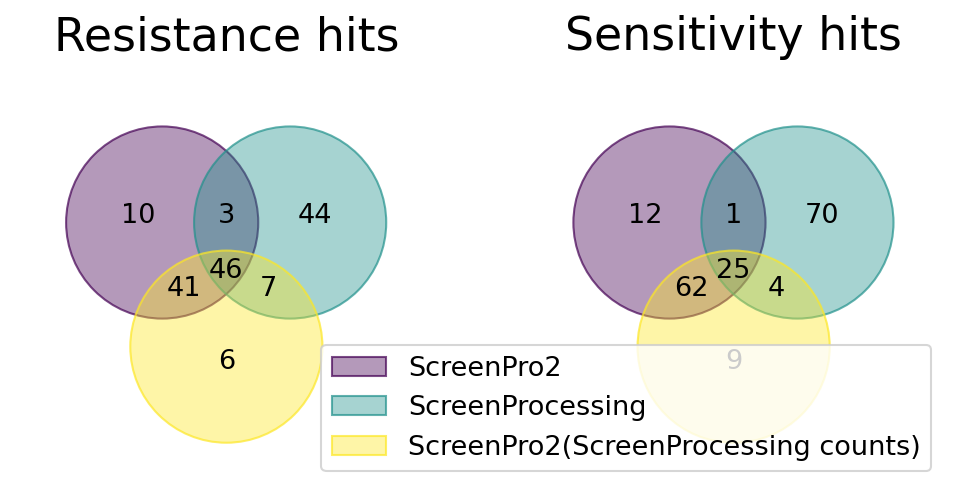

In [134]:
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(8,4), dpi=150)

## draw venn diagram
n_top_hits = 100

# resistance_hit
venn({
    'ScreenPro2':set(rho_screenpro2.dropna().sort_values('combined_score').tail(n_top_hits)['target'].to_list()),
    'ScreenProcessing':set(rho_screenprocessing.dropna().sort_values('combined_score').tail(n_top_hits)['target'].to_list()),
    'ScreenPro2(ScreenProcessing counts)':set(rho_screenpro2_with_screenprocessing_counts.dropna().sort_values('combined_score').tail(n_top_hits)['target'].to_list()),
}, ax=ax1, legend_loc=None)

ax1.set_title('Resistance hits', fontsize=22)

# sensitivity_hits
venn({
    'ScreenPro2':set(rho_screenpro2.dropna().sort_values('combined_score').head(n_top_hits)['target'].to_list()),
    'ScreenProcessing':set(rho_screenprocessing.dropna().sort_values('combined_score').head(n_top_hits)['target'].to_list()),
    'ScreenPro2(ScreenProcessing counts)':set(rho_screenpro2_with_screenprocessing_counts.dropna().sort_values('combined_score').head(n_top_hits)['target'].to_list()),
}, ax=ax2, legend_loc='lower right')

ax2.set_title('Sensitivity hits', fontsize=22)

plt.title('Sensitivity hits', fontsize=22)
plt.show()

In [135]:
def draw_rank_plot(df, col, ax, name_hits, pos_hits, neg_hits, q_thr=0.05):
    
    _, _ = scp.pl._rank.rank_plot(
        df,
        col,
        ylabel='',
        highlight_values_dict={
            '#3182bd': {
                'genes': neg_hits,
                'text': False
            },
            # 'black': {
            #     'genes': [
            #         g for g in p53_targets 
            #         if g in df[sensitivity_hit | resistant_hit]['target'].to_list()
            #     ],
            #     'text': False
            # },
            'black': {
                'genes': name_hits,
                'text': True
            },
            '#de2d26': {
                'genes': pos_hits,
                'text': False
            },
            # 'darkblue': {
            #     'genes': ['CHD8', 'SOX9', 'ACTB','RNF4', 'VPS37A','MYBL2'],
            #     'text': True
            # },
        },
        ax=ax,
        highlight_size_factor=20,
        dot_size=.1,
        title=col
    )
    
    ax.set_xlim(-1000,21000)
    ax.tick_params(width=0.5)
    for i in ax.spines.values(): i.set_linewidth(0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    # ax.spines['bottom'].set_visible(False)
    # ax.spines['left'].set_visible(False)
    for item in ([ax.title]):
        item.set_fontsize(8)
    for item in ([ax.xaxis.label, ax.yaxis.label]):
        item.set_fontsize(6)
    for item in ax.get_xticklabels() + ax.get_yticklabels():
        item.set_fontsize(6)
    
    # ax.hlines(df[col].quantile(q=q_thr), 0, 1, transform=ax.get_yaxis_transform(), linewidth=1, linestyles='-', colors='#3182bd')
    # ax.hlines(df[col].quantile(q=1-q_thr), 0, 1, transform=ax.get_yaxis_transform(), linewidth=1, linestyles='-', colors='#de2d26')

In [136]:
molm13_screenprocessing

In [137]:
rho_screenpro2[rho_screenpro2.sort_values('combined_score').target.str.contains('DCTD')]

/tmp/ipykernel_984843/3111188005.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  rho_screenpro2[rho_screenpro2.sort_values('combined_score').target.str.contains('DCTD')]


,target,transcript,score,ttest pvalue,BH adj_pvalue,number_of_guide_elements,combined_score,label
DCTD-P1P2,DCTD,P1P2,0.641772,0.000204,0.292152,3,22.96223,resistance_hit


In [138]:
molm13_screen

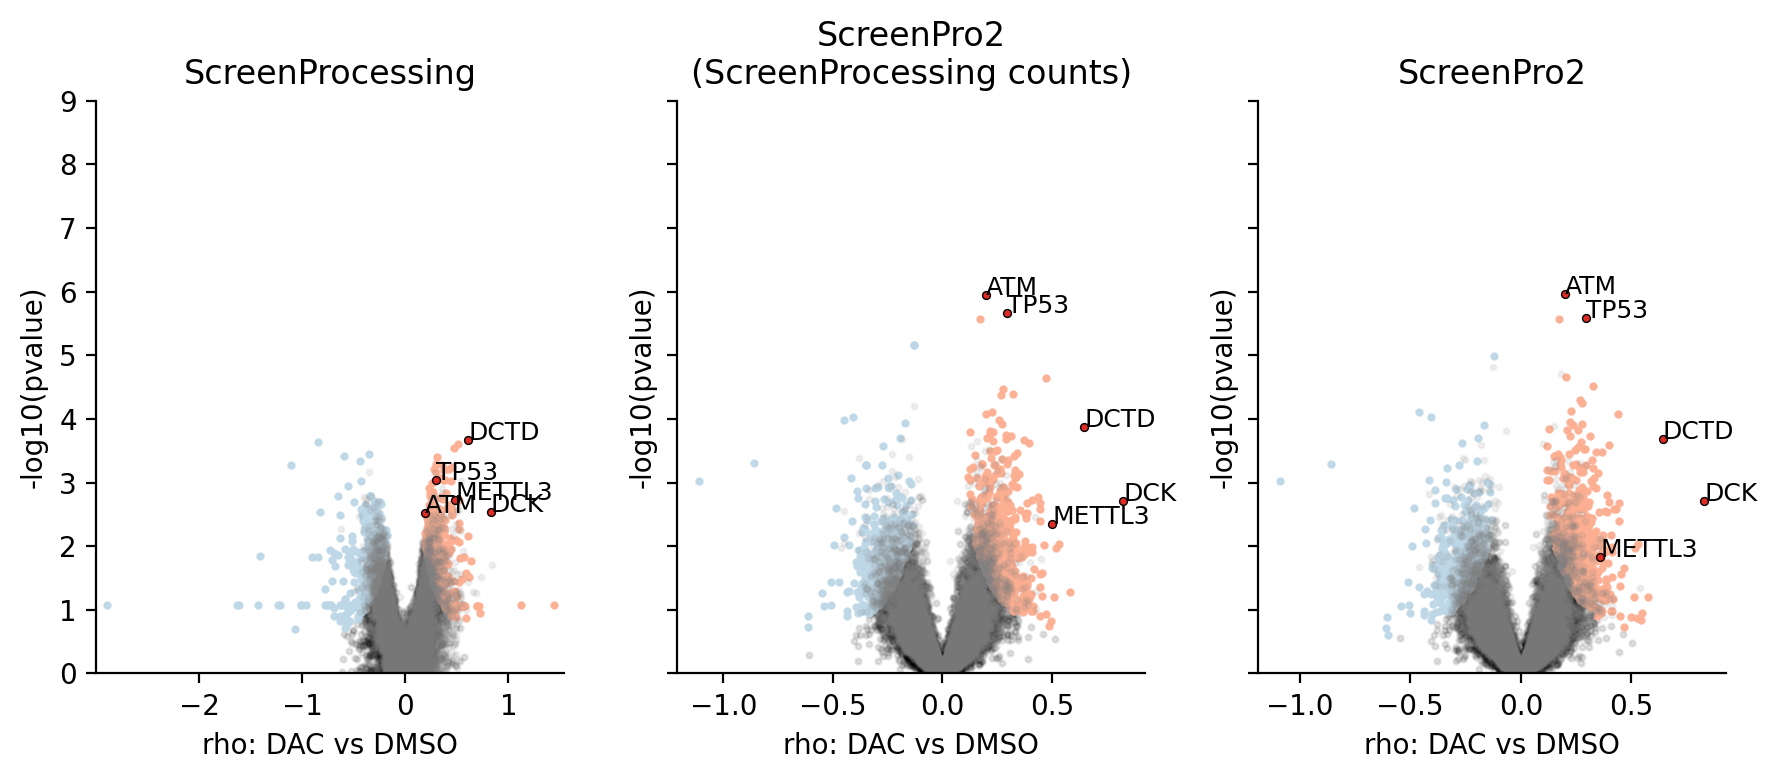

In [139]:
_, axes = plt.subplots(1,3,figsize=(9,4),dpi=200, sharey=True)


molm13_screenprocessing.drawVolcano(
    run_name='geneTable',
    phenotype_name='rho:DAC_vs_DMSO', 
    ax=axes[0], 
    score_col='average phenotype of strongest 3',
    pvalue_col='Mann-Whitney p-value', threshold=3,
    dot_size=4,
    resistance_hits=['DCK','DCTD','METTL3','TP53','ATM'],
    size_txt=9,
    t_x=0,
    t_y=0,
    ylims=[0,7],
    # xlims=[-3,2],
)
    
axes[0].set_title('ScreenProcessing')


molm13_screenprocessing.drawVolcano(
    run_name='compare_guides_top_3',
    phenotype_name='rho:DAC_vs_DMSO', 
    ax=axes[1], 
    pvalue_col='ttest pvalue', threshold=3,
    dot_size=4,
    resistance_hits=['DCK','DCTD','METTL3','TP53','ATM'],
    size_txt=9,
    ylims=[0,9],
    # xlims=[-3,3],
)

axes[1].set_title('ScreenPro2\n(ScreenProcessing counts)')


molm13_screen.drawVolcano(
    run_name='compare_guides_top_3',
    phenotype_name='rho:DAC_vs_DMSO', 
    ax=axes[2], 
    pvalue_col='ttest pvalue', threshold=3,
    dot_size=4,
    resistance_hits=['DCK','DCTD','METTL3','TP53','ATM'],
    size_txt=9,
    ylims=[0,9],
    # xlims=[-3,3],
    # x_
)

axes[2].set_title('ScreenPro2')


for ax in axes: 
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.get_legend().remove()

plt.tight_layout()
plt.show()

In [140]:
# dds = scp.ps.runDESeq(adata, 'condition')

In [141]:
# dds.var = adata.var.copy()

In [142]:
# _, ax = plt.subplots(1,1,figsize=(4,4),dpi=200)

# molm13_screen.drawVolcano(
#     run_name='pyDESeq2',
#     phenotype_name='rho:DAC_vs_DMSO', 
#     ax=ax,
#     score_col='log2FoldChange',
#     pvalue_col='pvalue', 
#     threshold=3,
#     dot_size=4,
#     resistance_hits=['DCK','DCTD','METTL3','TP53'],
#     size_txt=9,
#     # ylims=[0,9],
#     # xlims=[-3,3],
#     # x_
# )

___

/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(
/home/abe/miniconda3/envs/screenpro2/lib/python3.11/site-packages/pandas/plotting/_matplotlib/core.py:1388: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  scatter = ax.scatter(


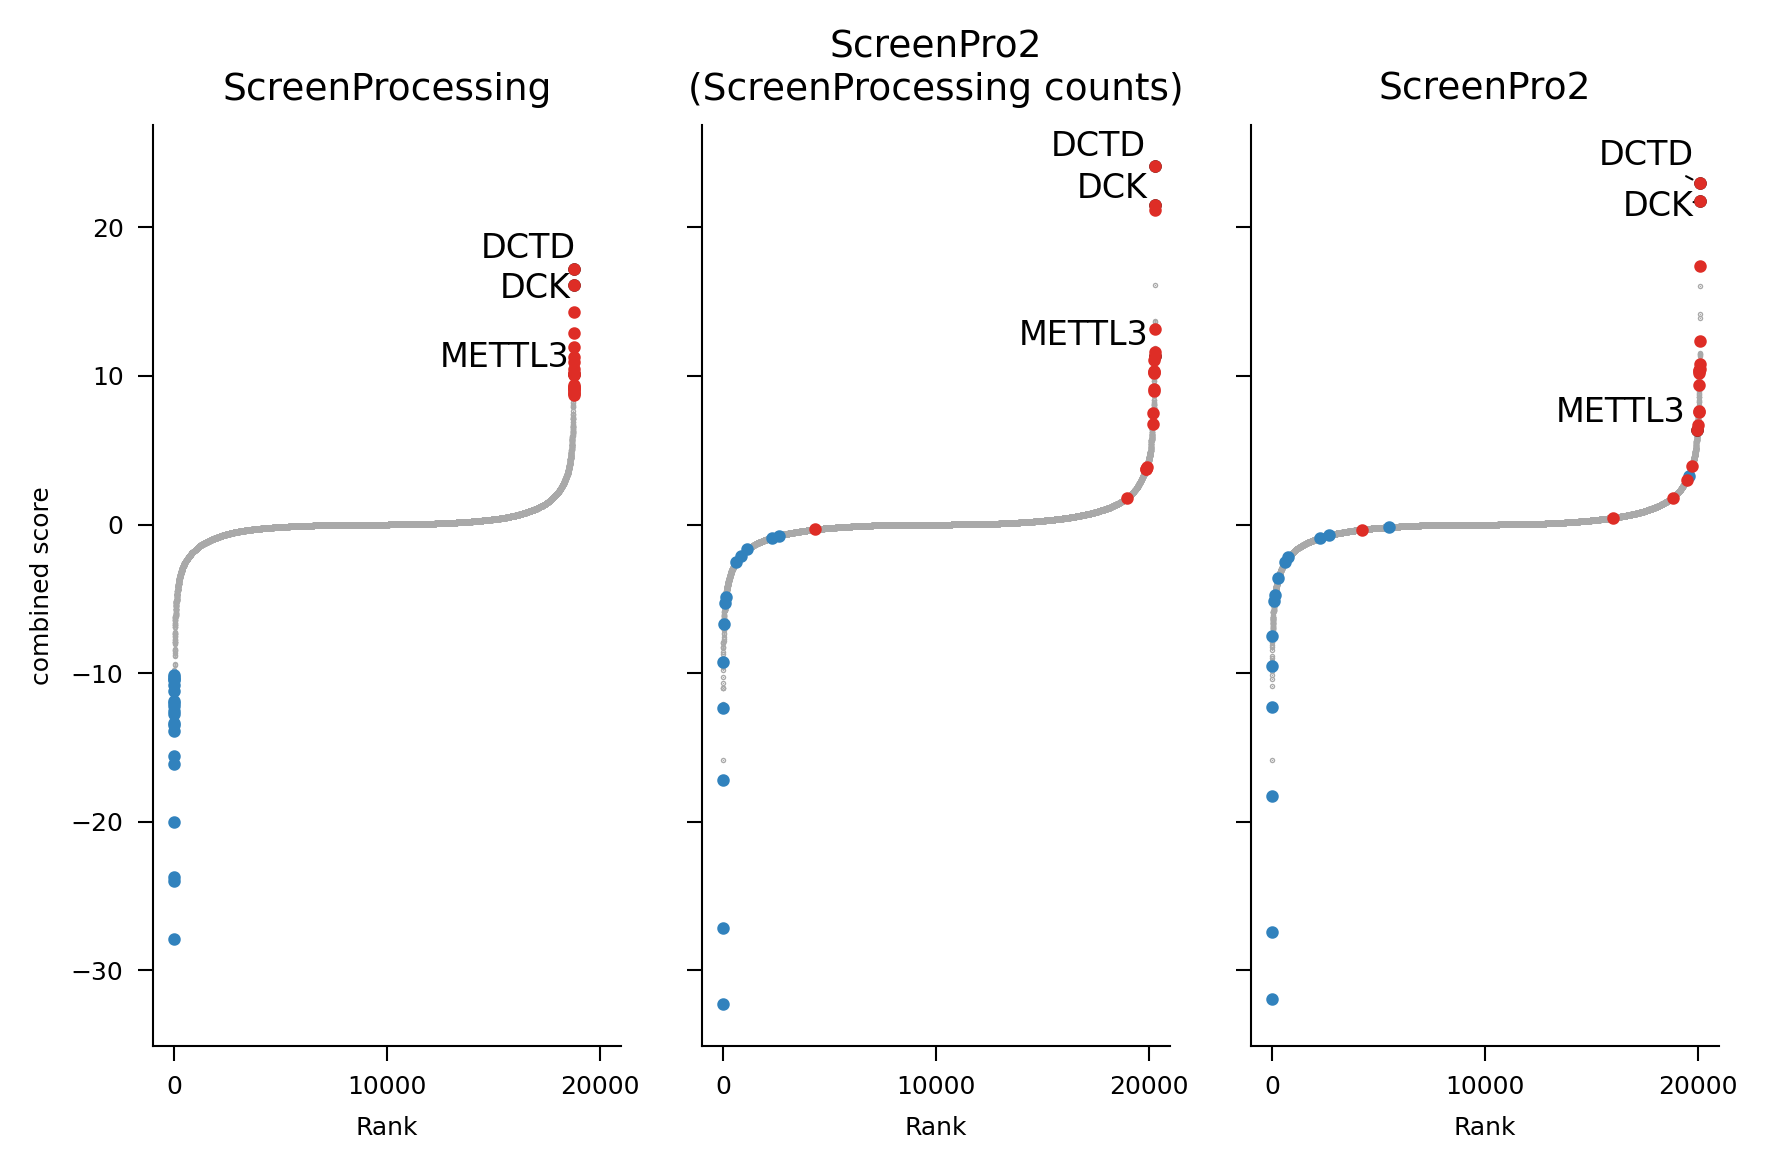

In [143]:
_, axes = plt.subplots(1,3,figsize=(6,4),sharey=True,dpi=300)

for ax, rho, title in zip(
    axes,
    [rho_screenprocessing,rho_screenpro2_with_screenprocessing_counts,rho_screenpro2],
    ['ScreenProcessing','ScreenPro2\n(ScreenProcessing counts)','ScreenPro2']
    ):
    draw_rank_plot(
        rho, 
        'combined_score',
        ax, 
        # q_thr=0.05,
        name_hits=['DCK','DCTD','METTL3'],
        pos_hits=rho_screenprocessing.query('target != "negative_control"').sort_values('combined_score').dropna().tail(20)['target'].to_list(),
        neg_hits=rho_screenprocessing.query('target != "negative_control"').sort_values('combined_score').dropna().head(20)['target'].to_list()
    )

    ax.set_title(title,fontsize=9)

axes[0].set_ylabel('combined score', fontsize=6)

# plt.title('ScreenPro2\nresults', fontsize=9)
plt.tight_layout()
plt.show()

## 

In [144]:
molm13_screen.buildPhenotypeData(run_name='compare_reps')

molm13_screen.pdata.obs['replicate'] = molm13_screen.pdata.obs.index.str[-1].astype(int)

In [145]:
molm13_screenprocessing.buildPhenotypeData(run_name='compare_reps')

molm13_screenprocessing.pdata.obs['replicate'] = molm13_screen.pdata.obs.index.str[-1].astype(int)

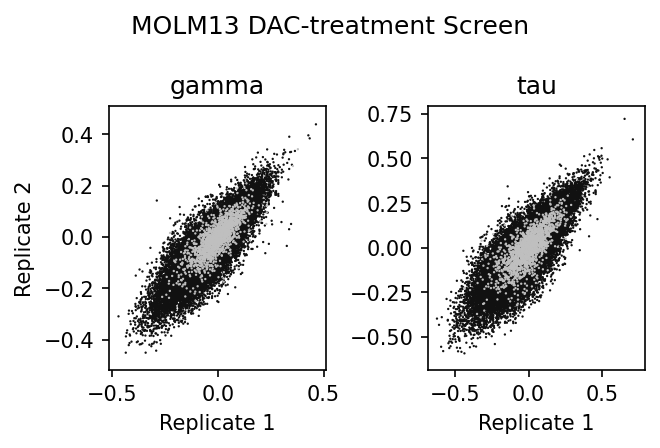

In [146]:
_, (ax1,ax2) = plt.subplots(1,2,figsize=(4.5,3),dpi=150)

scp.pl.plotReplicateScatter(ax1, molm13_screen.pdata,
                            'gamma:DMSO_vs_T0::replicate_1',
                            'gamma:DMSO_vs_T0::replicate_2', title='gamma',log_transform=False)
scp.pl.plotReplicateScatter(ax2, molm13_screen.pdata,
                            'tau:DAC_vs_T0::replicate_1',
                            'tau:DAC_vs_T0::replicate_2',
                            title='tau',log_transform=False)
ax2.set_ylabel('')

plt.suptitle('MOLM13 DAC-treatment Screen')
plt.tight_layout()
plt.show()

# 

In [147]:
# phe = pd.concat([
#     # get_replicate_score(screens['hl60'],'untreated', 'treated',
#     #                    molm13_db['untreated'] - molm13_db['treated'],
#     #                    ).add_prefix('hl60_rho_'),
    
#     # scp.ps.runPhenoScoreForReplicate(screens['hl60'],'T0', 'untreated',
#     #                    molm13_db['untreated']
#     #                    ).add_prefix('hl60_gamma_'),
    
#     # scp.ps.runPhenoScoreForReplicate(screens['hl60'],'T0', 'treated',
#     #                    molm13_db['treated'],
#     #                    ).add_prefix('hl60_tau_'),
    
#     # get_replicate_score(screens['molm13'],'DMSO', 'DAC',
#     #                    molm13_db['untreated'] - molm13_db['treated'],
#     #                    ).add_prefix('molm13_rho_'),
    
#     # scp.ps.runPhenoScoreForReplicate(screens['molm13'],'T0', 'DMSO',
#     #                    molm13_db['untreated'],
#     #                    ).add_prefix('molm13_gamma_'),
    
#     # scp.ps.runPhenoScoreForReplicate(screens['molm13'],'T0', 'DAC',
#     #                    molm13_db['treated'],
#     #                    ).add_prefix('molm13_tau_'),

#     # get_replicate_score(screens['skm1'],'DMSO', 'DAC',
#     #                     molm13_db['untreated'] - molm13_db['treated'],
#     #                    ).add_prefix('skm1_rho_'),
    
#     # scp.ps.runPhenoScoreForReplicate(screens['skm1'],'T0', 'DMSO',
#     #                     molm13_db['untreated']
#     #                    ).add_prefix('skm1_gamma_'),
    
#     # scp.ps.runPhenoScoreForReplicate(screens['skm1'],'T0', 'DAC',
#     #                     molm13_db['treated'],
#     #                    ).add_prefix('skm1_tau_'),
# ],axis=1).T

In [148]:
# pdata = ad.AnnData(X=phe,var=oligo)

# pdata.obs['cell_line'] = pdata.obs.index.str.split('_').str[0]
# pdata.obs['score'] = pdata.obs.index.str.split('_').str[1]
# pdata.obs['replicate'] = pdata.obs.index.str.split('_').str[-1]

# pdata_filt = pd.concat(dict([(line,screens[line].adata.var['low_count']) for line in screens]),axis=1).sum(axis=1).gt(0)

# pdata = pdata[:,~pdata_filt].copy()

In [150]:
# pdata0 = pdata.copy()

In [151]:
# pdata = pdata0[pdata0.obs.score.isin(['rho','gamma'])].copy()

### 

In [152]:
# sc.tl.pca(pdata)#, svd_solver='arpack')

In [153]:
# with rc_context({'figure.figsize': (3, 3)}):
#     sc.pl.pca_variance_ratio(pdata, n_pcs=8)
#     plt.tight_layout()
#     plt.show()

In [154]:
# with rc_context({'figure.figsize': (2, 2)}):
#     sc.pl.pca_scatter(pdata,color='score',size=300,alpha=0.7)
#     sc.pl.pca_scatter(pdata,color='cell_line',size=300,alpha=0.7)

In [155]:
# pca = plot_ggplot_pca(pdata,fill = 'cell_line',shape='score',legend_position=None,figure_size= (6, 3.5))

# 

In [149]:
%reload_ext watermark

In [150]:
%watermark

Last updated: 2026-03-06T01:54:25.443216-08:00

Python implementation: CPython
Python version       : 3.11.15
IPython version      : 9.10.0

Compiler    : GCC 14.3.0
OS          : Linux
Release     : 4.18.0-513.9.1.el8_9.x86_64
Machine     : x86_64
Processor   : x86_64
CPU cores   : 64
Architecture: 64bit



In [151]:
%watermark --iversions

anndata          : 0.11.4
blitzgsea        : 1.3.54
matplotlib       : 3.10.8
matplotlib_inline: 0.2.1
numpy            : 2.4.2
pandas           : 3.0.1
scanpy           : 1.11.0
scipy            : 1.17.1
screenpro        : 0.6.0
sklearn          : 1.5.2



In [152]:
!date

Fri Mar  6 01:54:26 PST 2026


___